# Solving the n-Queens Problem using Local Search

Student Name: 

I have used the following AI tools: 

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


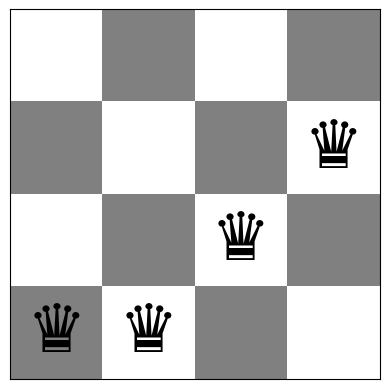

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


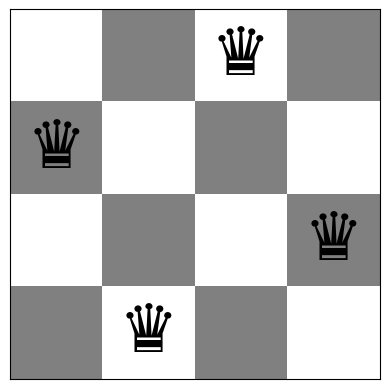

In [4]:
board = [1,3,0,2]
show_board(board)

# Bài 5. Biểu diễn bài toán n quân hậu

*Phần dưới đây bổ sung vào notebook đề; các ô gốc của đề được giữ nguyên.*

## Bài toán n quân hậu và cách biểu diễn
* **Mục tiêu:** đặt $n$ quân hậu lên bàn cờ $n \times n$ sao cho không có hai quân nào cùng hàng, cùng cột hoặc cùng đường chéo.
* **Không gian trạng thái:** mỗi cột có **đúng một** quân hậu. Một trạng thái ("board") là vector số nguyên $\mathbf{q} = (q_0, q_1, \dots, q_{n-1})$ với $q_i \in \{0, \dots, n-1\}$ là **chỉ số hàng** của quân hậu ở cột $i$. Ràng buộc "không cùng cột" được bảo đảm sẵn bởi cách biểu diễn nên không còn phải kiểm tra. Số trạng thái là $n^n$ (4⁴ = 256; 8⁸ = 16 777 216).
* **Hàm mục tiêu:** $h(\mathbf{q})$ = số **cặp** quân hậu cùng hàng hoặc cùng đường chéo.

### Định nghĩa hàm mục tiêu $h$

Hai quân ở cột $i < j$ (hàng $q_i$, $q_j$) **tấn công nhau** khi

$$ q_i = q_j \quad (\text{cùng hàng}) \qquad \text{hoặc} \qquad |q_i - q_j| = j - i \quad (\text{cùng đường chéo}). $$

(Cùng cột thì không thể xảy ra vì mỗi cột chỉ có một quân.) Khi đó

$$ h(\mathbf{q}) = \Big|\{(i, j) : 0 \le i < j \le n-1,\; q_i = q_j \ \text{hoặc}\ |q_i - q_j| = j - i\}\Big| = \sum_{i<j} \mathbb{1}\big[q_i = q_j \ \lor\ |q_i - q_j| = j - i\big]. $$

* Giá trị nhỏ nhất là $0$, lớn nhất là $\binom{n}{2}$ (mọi quân trên cùng một hàng hoặc một đường chéo).
* Một cặp có thể **không** đồng thời cùng hàng và cùng đường chéo (hai điều kiện loại trừ nhau khi $i \neq j$: cùng hàng thì $|q_i - q_j| = 0 \neq j - i$), nên không bị đếm trùng.
* **$h(\mathbf{q}) = 0 \iff$ không có cặp quân hậu nào tấn công nhau.** Chứng minh: $h$ là một tổng các số hạng $\mathbb{1}[\cdot] \in \{0, 1\}$ không âm, nên $h = 0$ khi và chỉ khi mọi số hạng bằng 0, tức là không có cặp $(i, j)$ nào thỏa điều kiện tấn công. Ta cũng kiểm tra bằng thực nghiệm ở bên dưới.

Hàm `conflicts(board)` của notebook không duyệt $O(n^2)$ cặp mà **đếm số quân trên từng hàng / từng đường chéo** rồi cộng $\binom{c}{2}$ cho mỗi nhóm có $c$ quân: một nhóm $c$ quân cùng đường thì có $\binom{c}{2}$ cặp tấn công nhau. Độ phức tạp $O(n)$. Hai cách tính phải cho cùng giá trị — ta sẽ kiểm chứng.

In [5]:
import itertools, json, os, time
os.makedirs('figs', exist_ok=True); os.makedirs('results', exist_ok=True)
RES = {}

## 5.2 Cài đặt $h$ theo định nghĩa (đếm từng cặp) và kiểm chứng với `conflicts()`
Hai hàm dưới đây **không dùng chung mã** với `conflicts()`, nên dùng làm "đáp án đối chứng".

In [6]:
def attacking_pairs(board):
    """Liệt kê các cặp (i, j), i < j, tấn công nhau - theo đúng định nghĩa."""
    n = len(board)
    return [(i, j) for i in range(n) for j in range(i + 1, n)
            if board[i] == board[j] or abs(board[i] - board[j]) == j - i]

def h(board):
    """Hàm mục tiêu theo định nghĩa: số cặp quân hậu cùng hàng hoặc cùng đường chéo (O(n^2))."""
    return len(attacking_pairs(board))

# ví dụ minh hoạ
for b in ([1, 3, 0, 2], [0, 1, 2, 3], [0, 0, 0, 0], [0, 2, 1, 3]):
    print(f"board = {b}: h = {h(b)}, conflicts = {conflicts(b)}, cặp tấn công = {attacking_pairs(b)}")

board = [1, 3, 0, 2]: h = 0, conflicts = 0, cặp tấn công = []
board = [0, 1, 2, 3]: h = 6, conflicts = 6, cặp tấn công = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
board = [0, 0, 0, 0]: h = 6, conflicts = 6, cặp tấn công = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
board = [0, 2, 1, 3]: h = 2, conflicts = 2, cặp tấn công = [(0, 3), (1, 2)]


**Kiểm chứng đầy đủ (exhaustive).** Với $n = 4, 5, 6$ ta duyệt **toàn bộ** $n^n$ bàn cờ; với $n = 8$ duyệt toàn bộ $8^8 = 16\,777\,216$ bàn cờ bằng numpy (tính $h$ theo định nghĩa theo từng cặp cột, vector hóa). Với mỗi bàn cờ kiểm tra (i) `conflicts(board) == h(board)` và (ii) `h == 0` khi và chỉ khi danh sách cặp tấn công rỗng; đồng thời đếm số bàn cờ có $h = 0$ (số nghiệm).

In [7]:
# --- n = 4, 5, 6: duyệt toàn bộ n^n bàn cờ bằng Python thuần ---
summary = []
for nn in (4, 5, 6):
    total = zero = 0
    for b in itertools.product(range(nn), repeat=nn):
        total += 1
        pairs = attacking_pairs(b)
        hv = conflicts(b)
        assert hv == len(pairs)                    # (i) hai cách tính trùng nhau
        assert (hv == 0) == (len(pairs) == 0)      # (ii) h = 0  <=>  không có cặp tấn công
        zero += (hv == 0)
    summary.append({'n': nn, 'boards': total, 'solutions': zero})
    print(f"n = {nn}: duyệt {total:,} bàn cờ, số bàn cờ h = 0: {zero}  -> kiểm chứng đạt")

# --- n = 8: duyệt toàn bộ 8^8 bàn cờ bằng numpy ---
def exhaustive_numpy(nn, chunk_first=1):
    """Duyệt mọi bàn cờ; cố định q0 = a (a = 0..n-1) để chia nhỏ bộ nhớ. Trả về (tổng, số h=0, histogram của h)."""
    total = 0; zero = 0; hist = {}
    rest = np.array(list(itertools.product(range(nn), repeat=nn - 1)), dtype=np.int8)   # n^(n-1) x (n-1)
    for a in range(nn):
        Q = np.concatenate([np.full((rest.shape[0], 1), a, dtype=np.int8), rest], axis=1)
        H = np.zeros(Q.shape[0], dtype=np.int16)
        for i in range(nn):
            for j in range(i + 1, nn):
                d = np.abs(Q[:, i].astype(np.int16) - Q[:, j].astype(np.int16))
                H += ((d == 0) | (d == j - i))
        total += Q.shape[0]; zero += int((H == 0).sum())
        vals, cnts = np.unique(H, return_counts=True)
        for v, c in zip(vals, cnts): hist[int(v)] = hist.get(int(v), 0) + int(c)
    return total, zero, hist

t0 = time.perf_counter()
tot8, zero8, hist8 = exhaustive_numpy(8)
print(f"n = 8: duyệt {tot8:,} bàn cờ, số bàn cờ h = 0: {zero8}  ({time.perf_counter() - t0:.1f} s)")
summary.append({'n': 8, 'boards': tot8, 'solutions': zero8})
RES['exhaustive'] = summary
RES['hist8_exact'] = hist8

n = 4: duyệt 256 bàn cờ, số bàn cờ h = 0: 2  -> kiểm chứng đạt
n = 5: duyệt 3,125 bàn cờ, số bàn cờ h = 0: 10  -> kiểm chứng đạt
n = 6: duyệt 46,656 bàn cờ, số bàn cờ h = 0: 4  -> kiểm chứng đạt
n = 8: duyệt 16,777,216 bàn cờ, số bàn cờ h = 0: 92  (5.2 s)


In [8]:
# đối chứng ngẫu nhiên: conflicts() == h() trên 20 000 bàn cờ n = 8 và 5 000 bàn cờ n = 12
rng_ok = 0
for nn, trials in ((8, 20000), (12, 5000)):
    for _ in range(trials):
        b = random_board(nn)
        assert conflicts(b) == h(b)
        assert (conflicts(b) == 0) == (len(attacking_pairs(b)) == 0)
        rng_ok += 1
print(f"{rng_ok:,} bàn cờ ngẫu nhiên: conflicts() == h() và (h=0 <=> không có cặp tấn công) đều đúng")

25,000 bàn cờ ngẫu nhiên: conflicts() == h() và (h=0 <=> không có cặp tấn công) đều đúng


**Kết luận kiểm chứng.** Với $n = 4, 5, 6, 8$ mọi bàn cờ đều thỏa `conflicts(board) == h(board)` và $h = 0 \iff$ không có cặp tấn công. Số nghiệm (bàn cờ có $h = 0$, mỗi cột một quân) là: $n = 4$: 2, $n = 5$: 10, $n = 6$: 4, $n = 8$: 92 — đúng bằng số cách đặt n quân hậu không tấn công nhau đã biết, nghĩa là biểu diễn "mỗi cột một quân" không bỏ sót nghiệm nào (vì ở nghiệm thật, mỗi cột bắt buộc có đúng một quân).

## 5.3 Bàn cờ n = 4 và n = 8: hiển thị cùng $h$
Hàm vẽ dưới đây vẽ bàn cờ, gạch nối đỏ giữa các cặp quân tấn công nhau, và ghi $h$ trong tiêu đề.

n = 4 ngẫu nhiên                         board = [3, 3, 2, 1]  h = 4  số cặp tấn công = 4
n = 4 nghiệm [1, 3, 0, 2]                board = [1, 3, 0, 2]  h = 0  số cặp tấn công = 0
n = 8 ngẫu nhiên                         board = [4, 4, 0, 1, 7, 1, 7, 1]  h = 8  số cặp tấn công = 8
n = 8 nghiệm [0, 4, 7, 5, 2, 6, 1, 3]    board = [0, 4, 7, 5, 2, 6, 1, 3]  h = 0  số cặp tấn công = 0


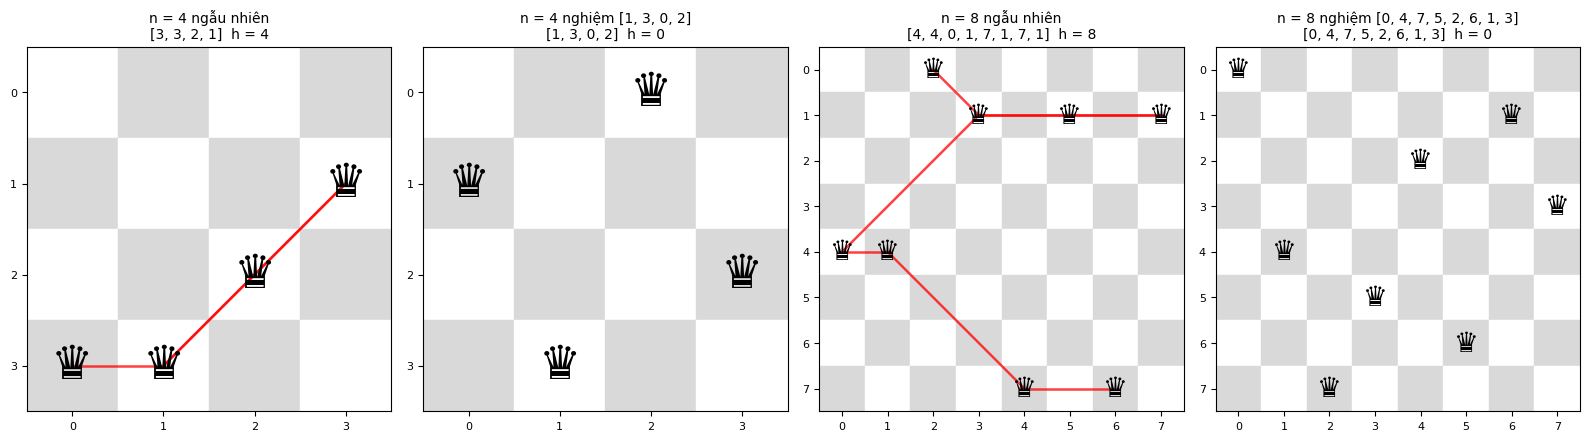

In [9]:
def draw_board(ax, board, title="", fontsize=None):
    n = len(board)
    fs = fontsize or {4: 34, 8: 20}.get(n, max(8, int(160 / n)))
    for i in range(n):
        for j in range(n):
            ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, color='#d9d9d9' if (i + j) % 2 else 'white'))
    for (i, j) in attacking_pairs(board):                       # đường nối các cặp tấn công
        ax.plot([i, j], [board[i], board[j]], color='red', lw=1.8, alpha=.75, zorder=2)
    for c in range(n):
        ax.text(c, board[c], u"\u265B", fontsize=fs, ha='center', va='center', zorder=3)
    ax.set_xlim(-.5, n - .5); ax.set_ylim(n - .5, -.5); ax.set_aspect('equal')
    ax.set_xticks(range(n)); ax.set_yticks(range(n)); ax.tick_params(labelsize=8)
    ax.set_title(title, fontsize=10)

np.random.seed(1234)
b4 = random_board(4);   b8 = random_board(8)
sol4 = [1, 3, 0, 2]
sol8 = [0, 4, 7, 5, 2, 6, 1, 3]        # một nghiệm quen thuộc của bài toán 8 quân hậu
boards = [(b4, "n = 4 ngẫu nhiên"), (sol4, "n = 4 nghiệm [1, 3, 0, 2]"),
          (b8, "n = 8 ngẫu nhiên"), (sol8, "n = 8 nghiệm [0, 4, 7, 5, 2, 6, 1, 3]")]
fig, axs = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, (b, t) in zip(axs, boards):
    draw_board(ax, b, f"{t}\n{list(map(int, b))}  h = {conflicts(b)}")
    print(f"{t:40s} board = {list(map(int, b))}  h = {conflicts(b)}  số cặp tấn công = {len(attacking_pairs(b))}")
plt.tight_layout(); plt.savefig('figs/fig5_ban_co.png', dpi=150, bbox_inches='tight'); plt.show()
assert conflicts(sol4) == 0 and conflicts(sol8) == 0

Hiển thị bằng `show_board()` của notebook gốc cho hai bàn cờ ngẫu nhiên (n = 4 và n = 8) và nghiệm n = 8:

Board with 4 conflicts.


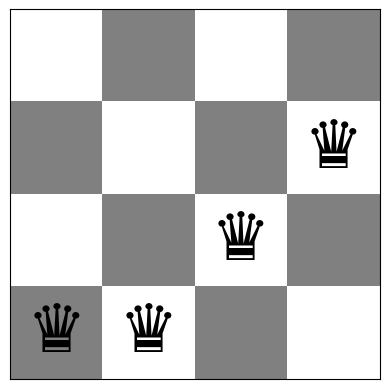

Board with 8 conflicts.


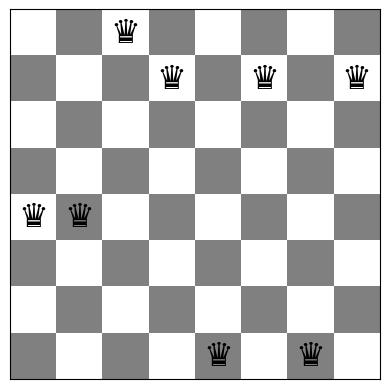

Board with 0 conflicts.


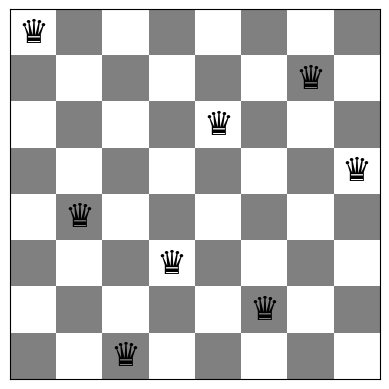

In [10]:
show_board(b4)
show_board(b8, fontsize=24)
show_board(sol8, fontsize=24)

## 5.4 Phân bố của $h$ trên bàn cờ ngẫu nhiên
Để hiểu độ khó của việc tìm nghiệm bằng cách đoán ngẫu nhiên: với $n = 8$, ta đã đếm chính xác phân bố của $h$ trên **toàn bộ** $8^8$ bàn cờ ở trên (`hist8`); với $n = 4$ phân bố trên toàn bộ 256 bàn cờ.

n = 4: tổng 256 bàn cờ; h trung bình = 3.250; h nhỏ nhất = 0; h lớn nhất = 6; tỉ lệ h = 0: 2/256 = 7.812e-03
n = 8: tổng 16,777,216 bàn cờ; h trung bình = 7.875; h nhỏ nhất = 0; h lớn nhất = 28; tỉ lệ h = 0: 92/16,777,216 = 5.484e-06


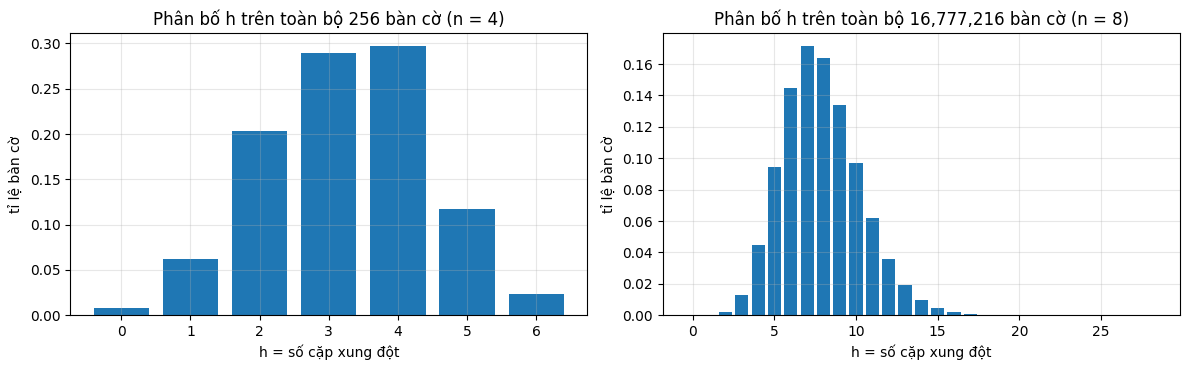

n = 4: số láng giềng của mỗi bàn cờ = n(n-1) = 12
n = 8: số láng giềng của mỗi bàn cờ = n(n-1) = 56


In [11]:
hist4 = {}
for b in itertools.product(range(4), repeat=4):
    v = conflicts(b); hist4[v] = hist4.get(v, 0) + 1

def stats(hist):
    tot = sum(hist.values())
    mean = sum(k * v for k, v in hist.items()) / tot
    return tot, mean

for nn, hist in ((4, hist4), (8, hist8)):
    tot, mean = stats(hist)
    print(f"n = {nn}: tổng {tot:,} bàn cờ; h trung bình = {mean:.3f}; h nhỏ nhất = {min(hist)}; h lớn nhất = {max(hist)}; "
          f"tỉ lệ h = 0: {hist[0]}/{tot:,} = {hist[0]/tot:.3e}")
RES['hist4'] = {int(k): int(v) for k, v in hist4.items()}
RES['stats'] = {'n4_mean': stats(hist4)[1], 'n8_mean': stats(hist8)[1],
                'n4_p0': hist4[0] / 256, 'n8_p0': hist8[0] / 8**8}

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (nn, hist) in zip(axs, ((4, hist4), (8, hist8))):
    ks = sorted(hist); tot = sum(hist.values())
    ax.bar(ks, [hist[k] / tot for k in ks], color='tab:blue')
    ax.set_title(f"Phân bố h trên toàn bộ {tot:,} bàn cờ (n = {nn})")
    ax.set_xlabel("h = số cặp xung đột"); ax.set_ylabel("tỉ lệ bàn cờ"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('figs/fig6_phan_bo_h.png', dpi=150, bbox_inches='tight'); plt.show()

# số láng giềng của một trạng thái theo toán tử "đổi hàng của một quân"
for nn in (4, 8): print(f"n = {nn}: số láng giềng của mỗi bàn cờ = n(n-1) = {nn*(nn-1)}")
json.dump(RES, open('results/nq_results.json', 'w'), indent=1)

## 5.5 Nhận xét

* Mỗi cột đúng một quân hậu nên không gian trạng thái giảm từ $\binom{n^2}{n}$ xuống $n^n$ và ràng buộc "không cùng cột" luôn thỏa. Chỉ còn hai họ ràng buộc nhị phân: cùng hàng và cùng đường chéo.
* $h$ là một hàm mục tiêu cần **cực tiểu hóa** với giá trị tối ưu đã biết là 0; nghiệm = bàn cờ có $h = 0$. Tính $h$ bằng đếm theo hàng/đường chéo chỉ tốn $O(n)$, rẻ hơn $O(n^2)$ khi đếm từng cặp, điều quan trọng khi các thuật toán Hill Climbing phải gọi $h$ rất nhiều lần (Bài 6–8).
* Nghiệm rất hiếm: 2 trên 256 bàn cờ (n = 4) và 92 trên 16 777 216 (n = 8, ≈ 5,5·10⁻⁶), vì vậy đoán ngẫu nhiên không hiệu quả và cần tìm kiếm cục bộ có định hướng.

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

In [12]:
import time
rng = np.random.RandomState(2024)     # hạt giống riêng cho các thí nghiệm Bài 6-7 (tái lập được)

def best_neighbors(board, cur):
    """Duyệt TOÀN BỘ n(n-1) láng giềng (đổi hàng của 1 quân trong cột của nó).
    Trả về (số lần gọi conflicts, danh sách (cột, hàng, h) của mọi nước làm giảm h, h nhỏ nhất tìm thấy)."""
    n = len(board); evals = 0; improving = []; best = cur
    for col in range(n):
        old = board[col]
        for row in range(n):
            if row == old: continue
            board[col] = row
            h_new = conflicts(board); evals += 1
            if h_new < cur: improving.append((col, row, h_new))
            if h_new < best: best = h_new
        board[col] = old                      # trả lại trạng thái cũ
    return evals, improving, best

In [13]:
def steepest_ascent(board):
    """Task 1: Steepest-ascent HC. Mỗi bước đánh giá mọi láng giềng, chọn nước TỐT NHẤT (hòa -> chọn ngẫu nhiên).
    Dừng khi h = 0 (nghiệm) hoặc không còn nước nào làm giảm h (cực trị cục bộ / plateau)."""
    board = np.array(board).copy()
    cur = conflicts(board); evals = 1; steps = 0; hist = [cur]
    while cur > 0:
        e, improving, best = best_neighbors(board, cur)
        evals += e
        if not improving: break                                   # kẹt: local optimum
        best_moves = [m for m in improving if m[2] == best]
        col, row, cur = best_moves[rng.randint(len(best_moves))]  # chọn ngẫu nhiên trong các nước tốt nhất
        board[col] = row; steps += 1; hist.append(cur)
    return {'board': board, 'h': cur, 'steps': steps, 'evals': evals, 'hist': hist, 'stuck': cur > 0}

# chạy minh hoạ 1 lần trên bàn cờ ngẫu nhiên n = 8
np.random.seed(7)
b0 = random_board(8)
print("Bàn cờ ban đầu:", b0.tolist(), "h =", conflicts(b0))
r = steepest_ascent(b0)
print("Kết quả      :", r['board'].tolist(), "h =", r['h'], "| số bước =", r['steps'], "| số lần gọi conflicts =", r['evals'],
      "| kẹt local optimum:", r['stuck'])
print("h qua các bước:", r['hist'])

Bàn cờ ban đầu: [7, 4, 1, 6, 3, 3, 7, 7] h = 7
Kết quả      : [2, 5, 1, 6, 0, 3, 7, 4] h = 0 | số bước = 4 | số lần gọi conflicts = 225 | kẹt local optimum: False
h qua các bước: [7, 4, 2, 1, 0]


**Cách cài đặt.** Một nước đi = đổi hàng của một quân trong cột của nó, nên mỗi bàn cờ có $n(n-1)$ láng giềng (56 với n = 8). Mỗi bước: (1) duyệt toàn bộ láng giềng và tính `conflicts()` cho từng cái; (2) lấy các nước làm **giảm** h, chọn nước có h nhỏ nhất (hòa thì chọn ngẫu nhiên, tránh thiên vị theo thứ tự duyệt); (3) lặp lại. **Điều kiện dừng:** h = 0 (nghiệm), hoặc không còn nước nào làm giảm h hẳn (cực trị cục bộ; các nước đi ngang/plateau không được chấp nhận nên không có nguy cơ lặp vô hạn, vì h giảm nghiêm ngặt ở mỗi bước). Mỗi bước giá trị h giảm ít nhất 1 nên tối đa $\binom{n}{2}$ bước. Ở lần chạy minh hoạ, h giảm 7 → 4 → 2 → 1 → 0 sau 4 bước và 225 lần gọi `conflicts()` (= 1 + 4×56).

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [14]:
def inefficient_stochastic(board):
    """Task 2: Inefficient Stochastic HC. Vẫn đánh giá mọi láng giềng, nhưng chọn NGẪU NHIÊN một nước trong
    tất cả các nước làm giảm h (không nhất thiết là nước tốt nhất)."""
    board = np.array(board).copy()
    cur = conflicts(board); evals = 1; steps = 0; hist = [cur]
    while cur > 0:
        e, improving, best = best_neighbors(board, cur)
        evals += e
        if not improving: break
        col, row, cur = improving[rng.randint(len(improving))]
        board[col] = row; steps += 1; hist.append(cur)
    return {'board': board, 'h': cur, 'steps': steps, 'evals': evals, 'hist': hist, 'stuck': cur > 0}

r = inefficient_stochastic(b0)
print("Bàn cờ ban đầu:", b0.tolist(), "h =", conflicts(b0))
print("Kết quả      :", r['board'].tolist(), "h =", r['h'], "| số bước =", r['steps'], "| số lần gọi conflicts =", r['evals'],
      "| kẹt local optimum:", r['stuck'])
print("h qua các bước:", r['hist'])

Bàn cờ ban đầu: [7, 4, 1, 6, 3, 3, 7, 7] h = 7
Kết quả      : [2, 5, 1, 6, 3, 0, 7, 4] h = 1 | số bước = 5 | số lần gọi conflicts = 337 | kẹt local optimum: True
h qua các bước: [7, 5, 4, 3, 2, 1]


**Cách cài đặt.** Giống Task 1 (vẫn đánh giá đủ $n(n-1)$ láng giềng ở mỗi bước, nên chi phí mỗi bước như nhau) nhưng nước đi được chọn **ngẫu nhiên đều** trong tất cả các nước làm giảm h, không nhất thiết là nước tốt nhất. Điều kiện dừng như Task 1. Cũng vì vậy đây là biến thể "kém hiệu quả": đã tốn công tính hết các láng giềng mà vẫn bỏ qua thông tin về nước tốt nhất. Ở lần chạy minh hoạ trên cùng bàn cờ ban đầu, thuật toán kẹt ở h = 1 sau 5 bước, trong khi Task 1 đạt h = 0.

In [15]:
def run_many(algo, n, runs=100, seed=0):
    """Chạy algo từ `runs` bàn cờ ngẫu nhiên KHÁC NHAU (cùng dãy bàn cờ cho mọi thuật toán nhờ cùng seed)."""
    np.random.seed(seed)
    boards = [random_board(n) for _ in range(runs)]
    out = []
    for b in boards:
        t0 = time.perf_counter(); r = algo(b); r['time'] = time.perf_counter() - t0
        assert conflicts(r['board']) == r['h']                 # kiểm tra h báo cáo khớp bàn cờ cuối
        out.append(r)
    return out

def summarize(res):
    return {'runs': len(res),
            'success_%': 100 * np.mean([r['h'] == 0 for r in res]),
            'avg_final_h': np.mean([r['h'] for r in res]),
            'avg_steps': np.mean([r['steps'] for r in res]),
            'avg_evals': np.mean([r['evals'] for r in res]),
            'avg_time_s': np.mean([r['time'] for r in res]),
            'stuck_runs': sum(r['stuck'] for r in res)}

import pandas as pd
RES_HC = {}
rows = []
for n in (4, 8):
    for name, algo in (('Steepest HC', steepest_ascent), ('Ineff. Stochastic HC', inefficient_stochastic)):
        res = run_many(algo, n, runs=100, seed=100 + n)
        RES_HC[(n, name)] = res
        s = summarize(res); rows.append({'n': n, 'Thuật toán': name, **s})
df_hc = pd.DataFrame(rows)
pd.set_option('display.width', 200)
print(df_hc.round(4).to_string(index=False))

 n           Thuật toán  runs  success_%  avg_final_h  avg_steps  avg_evals  avg_time_s  stuck_runs
 4          Steepest HC   100       41.0         0.66       1.66      28.00      0.0002          59
 4 Ineff. Stochastic HC   100       27.0         0.83       1.97      33.40      0.0002          73
 8          Steepest HC   100       17.0         1.24       3.35     235.08      0.0024          83
 8 Ineff. Stochastic HC   100       16.0         1.27       4.99     327.48      0.0034          84


**So sánh 100 lượt (cùng 100 bàn cờ khởi tạo cho hai thuật toán, mỗi n).**

* **Tỉ lệ thành công thấp:** n = 8 chỉ khoảng 16–17 % (Steepest 17 %, Inefficient Stochastic 16 %); n = 4 là 41 % và 27 %. Phần còn lại **mắc kẹt ở cực trị cục bộ** (cột `stuck_runs`: 83 và 84 trên 100 lượt ở n = 8), thường với h cuối bằng 1 hoặc 2: có những bàn cờ chỉ còn một cặp xung đột nhưng mọi nước đi một quân đều làm h tăng hoặc không đổi. Hill Climbing không chấp nhận nước đi tệ hơn hay đi ngang, nên không thoát được.
* **n = 4 lại thấp hơn mong đợi** vì bài toán có chỉ 2 nghiệm trên 256 trạng thái, và có nhiều trạng thái h = 1, 2 mà láng giềng đều tệ hơn.
* **Số bước:** Steepest cần ít bước hơn (n = 8: 3,35 so với 4,99) vì luôn chọn nước giảm nhiều nhất; Inefficient có thể chọn nước giảm chỉ 1 đơn vị.
* **Số lần đánh giá hàm mục tiêu:** Steepest 235 và Inefficient 327 (n = 8). Cả hai đều tốn đúng $n(n-1) = 56$ lần cho mỗi bước (kể cả bước cuối cùng để phát hiện kẹt), nên chi phí tỉ lệ với số bước; Inefficient tốn hơn vì cần nhiều bước hơn. Thời gian trung bình mỗi lượt vì thế cũng cao hơn ở Inefficient (xem bảng; chỉ cỡ mili-giây nên nhiễu đo lớn).
* Sự khác biệt về tỉ lệ thành công giữa hai thuật toán ở n = 8 (17 % so với 16 %) **nằm trong sai số** của 100 lượt (độ lệch chuẩn ≈ 3,8 điểm phần trăm), nên không kết luận được thuật toán nào thành công nhiều hơn; chỉ khác biệt về số bước/số lần đánh giá là rõ ràng.

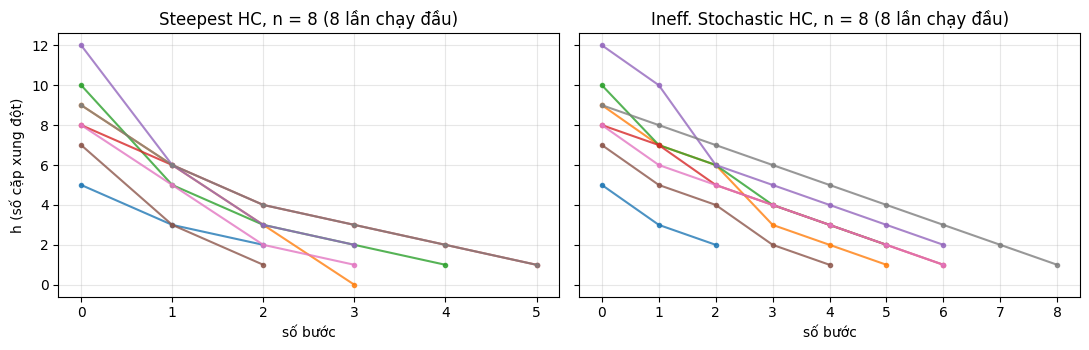

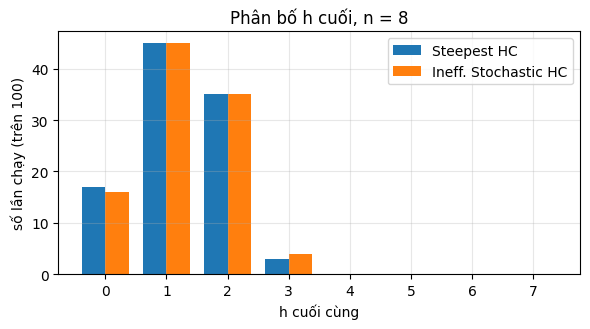

In [16]:
# đồ thị h theo số bước cho 5 lần chạy đầu của mỗi thuật toán (n = 8)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, name in zip(axs, ('Steepest HC', 'Ineff. Stochastic HC')):
    for r in RES_HC[(8, name)][:8]:
        ax.plot(r['hist'], marker='o', ms=3, alpha=.8)
    ax.set_title(f"{name}, n = 8 (8 lần chạy đầu)"); ax.set_xlabel("số bước"); ax.grid(alpha=.3)
axs[0].set_ylabel("h (số cặp xung đột)")
plt.tight_layout(); plt.savefig('figs/fig7_hc_hoi_tu.png', dpi=150, bbox_inches='tight'); plt.show()

# phân bố h cuối (n = 8)
fig, ax = plt.subplots(figsize=(6, 3.4))
w = .38
for k, name in enumerate(('Steepest HC', 'Ineff. Stochastic HC')):
    vals = [r['h'] for r in RES_HC[(8, name)]]
    ks = range(0, 8)
    ax.bar([x + (k - .5) * w for x in ks], [vals.count(x) for x in ks], width=w, label=name)
ax.set_xlabel("h cuối cùng"); ax.set_ylabel("số lần chạy (trên 100)"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Phân bố h cuối, n = 8")
plt.tight_layout(); plt.savefig('figs/fig8_hc_h_cuoi.png', dpi=150, bbox_inches='tight'); plt.show()

Ở hình trái/phải, h giảm rất nhanh trong 2–3 bước đầu rồi dừng (đường chấm kết thúc sớm), đúng với con số trung bình 3–5 bước. Biểu đồ cột cho thấy phần lớn các lượt không thành công dừng ở h = 1 hoặc h = 2, và Steepest có số lượt h = 0 nhỉnh hơn một chút.

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

### Chuẩn bị chung cho các thuật toán

* **Láng giềng (nước đi cục bộ):** chọn một cột `c` và chuyển quân ở cột đó sang một hàng `r ≠ board[c]`. Mỗi bàn cờ có `n(n−1)` láng giềng.
* **Đếm số lần đánh giá hàm mục tiêu:** mình bọc `conflicts()` trong hàm `h()` có biến đếm `EVALS`. Mọi thuật toán dưới đây đều gọi `h()` (không gọi thẳng `conflicts()`), nên số lần đánh giá được đo công bằng.
* **Kết quả mỗi lượt chạy** là một dict gồm bàn cờ cuối, `h` cuối, số vòng lặp `iters`, số lần đánh giá `evals`, lịch sử `hist_h` (giá trị `h` sau mỗi vòng lặp) và `hist_e` (số lần đánh giá tích luỹ), dùng để vẽ đồ thị hội tụ.
* Khi có nhiều nước đi tốt bằng nhau, thuật toán chọn **ngẫu nhiên** giữa chúng (không lấy cái đầu tiên) để tránh thiên lệch.

In [17]:
EVALS = 0   # tổng số lần đánh giá hàm mục tiêu

def h(board):
    # Hàm mục tiêu h(board) = conflicts(board), có đếm số lần gọi.
    global EVALS
    EVALS += 1
    return conflicts(board)

def sample_neighbor(board):
    # Sinh MỘT láng giềng ngẫu nhiên: (cột c, hàng mới r) với r khác hàng hiện tại.
    n = len(board)
    c = np.random.randint(n)
    r = np.random.randint(n - 1)
    if r >= board[c]:          # bỏ qua hàng hiện tại để r phân phối đều trên n-1 hàng còn lại
        r += 1
    return c, r

def make_result(board, cur, iters, e0, hist_h, hist_e, **extra):
    d = dict(board=board, h=cur, iters=iters, evals=EVALS - e0, hist_h=hist_h, hist_e=hist_e)
    d.update(extra)
    return d

In [18]:
# Adapters for later experiments; Nhi Task 1-2 implementations above are unchanged.
def _adapt_nhi_result(result):
    result = dict(result)
    result["iters"] = result.get("steps", 0)
    result["hist_h"] = result.get("hist", [result["h"]])
    result["hist_e"] = []
    return result

def steepest_hc(board, **kwargs):
    return _adapt_nhi_result(steepest_ascent(board))

def inefficient_stochastic_hc(board, **kwargs):
    return _adapt_nhi_result(inefficient_stochastic(board))


## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way:

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state.
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

**Cách làm và điều kiện dừng.** Mỗi vòng lặp chỉ sinh **một** láng giềng ngẫu nhiên (`sample_neighbor`), đánh giá nó (1 lần gọi `h`) và nhận nếu `h` mới `<` `h` hiện tại; ngược lại bỏ qua.

Vì không bao giờ xem hết các láng giềng, không thể biết chắc mình đang ở cực trị cục bộ. Mình dùng điều kiện dừng: **dừng khi `patience` lần thử liên tiếp đều không cải thiện** (hoặc khi `h = 0`; thêm `max_iters` để chắc chắn không lặp vô hạn).

*Chọn `patience` thế nào?* Có `N = n(n−1)` láng giềng, và ta lấy mẫu **có hoàn lại**. Xác suất một láng giềng cụ thể (ví dụ một nước cải thiện duy nhất) **không** được chọn sau `x` lần thử là `(1 − 1/N)^x ≈ e^(−x/N)`. Chọn `x = 3N` thì xác suất bỏ sót chỉ còn khoảng `e^−3 ≈ 5%` (và nếu có nhiều nước cải thiện thì còn thấp hơn nhiều). Vậy mình đặt

$$\text{patience} = 3\,n\,(n-1)$$

Phần sau có một thí nghiệm nhỏ thay đổi hệ số này (0,5N → 5N) để kiểm tra lập luận.

In [19]:
def stochastic_hc(board, patience_factor=3, max_iters=100000):
    # Task 3: Stochastic (first-choice) hill climbing: mỗi vòng lặp sinh 1 láng giềng, nhận nếu tốt hơn.
    # Dừng khi h = 0, hoặc khi `patience` lần thử liên tiếp không cải thiện.
    board = np.array(board).copy()
    n = len(board)
    patience = int(patience_factor * n * (n - 1))
    e0 = EVALS
    cur = h(board)
    hist_h, hist_e = [cur], [0]
    fails, iters = 0, 0

    while cur > 0 and fails < patience and iters < max_iters:
        c, r = sample_neighbor(board)
        old = board[c]
        board[c] = r
        v = h(board)
        if v < cur:                 # chỉ nhận nước cải thiện thật sự
            cur = v
            fails = 0
        else:
            board[c] = old          # hoàn tác
            fails += 1
        iters += 1
        hist_h.append(cur); hist_e.append(EVALS - e0)

    stuck = None if cur == 0 else ('patience' if fails >= patience else 'max_iters')
    return make_result(board, cur, iters, e0, hist_h, hist_e, stuck=stuck)

np.random.seed(7)
b0 = random_board(8)
r3 = stochastic_hc(b0)
print(f"Efficient Stochastic HC: h cuối = {r3['h']}, số vòng lặp = {r3['iters']}, số lần đánh giá = {r3['evals']}, dừng vì: {r3['stuck']}")

Efficient Stochastic HC: h cuối = 2, số vòng lặp = 226, số lần đánh giá = 227, dừng vì: patience


**Thí nghiệm nhỏ: ảnh hưởng của `patience`** (n = 8, 200 bàn cờ ngẫu nhiên giống nhau cho mọi hệ số). Nếu lập luận đúng thì tăng hệ số trên 3 gần như không tăng tỉ lệ thành công mà chỉ làm tốn thêm lượt đánh giá.

In [20]:
np.random.seed(100)
boards_pat = [random_board(8) for _ in range(200)]
rows = []
for fac in (0.5, 1, 2, 3, 5):
    np.random.seed(101)
    rs = [stochastic_hc(b, patience_factor=fac) for b in boards_pat]
    rows.append([f"{fac} * N  (patience = {int(fac * 56)})", 100 * np.mean([r['h'] == 0 for r in rs]),
                 np.mean([r['h'] for r in rs]), np.mean([r['evals'] for r in rs])])
pd.DataFrame(rows, columns=["patience", "% thành công (h = 0)", "h cuối TB", "Số lần đánh giá TB"]).round(2)

,patience,% thành công (h = 0),h cuối TB,Số lần đánh giá TB
0,0.5 * N (patience = 28),2.5,2.04,52.96
1,1 * N (patience = 56),7.0,1.60,90.82
2,2 * N (patience = 112),10.5,1.41,155.15
3,3 * N (patience = 168),13.0,1.35,204.52
4,5 * N (patience = 280),17.0,1.23,313.94


Kết quả cho thấy lập luận **chỉ đúng một phần**: tăng `patience` đúng là làm chi phí tăng gần tuyến tính, nhưng tỉ lệ thành công cũng tăng đều (2,5% → 7% → 10,5% → 13% → 17%) chứ không bão hoà ngay tại `3N`. Lí do là Efficient HC có thể thoát khỏi một trạng thái "tưởng là kẹt" bằng nước đi cải thiện hiếm (nhiều khi chỉ 1 trong 56 láng giềng), và `patience` nhỏ khiến nó bỏ cuộc sớm. Hệ số `3N` là một thoả hiệp (bỏ sót một nước cải thiện duy nhất với xác suất ~5%); tăng lên `5N` có lợi thêm chút nhưng tốn thêm ~50% số lần đánh giá. Mình giữ `3N` cho mọi thí nghiệm sau.

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

**Cách làm.** Hàm `random_restart` bọc một thuật toán hill climbing bất kỳ: chạy từ một bàn cờ ngẫu nhiên; nếu chưa đạt `h = 0` thì sinh bàn cờ ngẫu nhiên mới và chạy lại, **tối đa 100 lần khởi động lại** (tức tối đa 101 lượt chạy, gồm lượt đầu và 100 lần restart). Hàm trả về bàn cờ tốt nhất, số restart đã dùng, tổng số lần đánh giá và tổng thời gian.

Mình lặp lại toàn bộ quy trình này 100 lần độc lập cho mỗi (thuật toán, n) để thống kê.

In [21]:
def random_restart(algorithm, n, max_restarts=100, **kw):
    # Hill climbing với random restart. Dùng được cho steepest_hc, inefficient_stochastic_hc, stochastic_hc.
    t0 = time.perf_counter()
    best, total_evals, total_iters = None, 0, 0
    for restart in range(max_restarts + 1):
        r = algorithm(random_board(n), **kw)
        total_evals += r['evals']; total_iters += r['iters']
        if best is None or r['h'] < best['h']:
            best = r
        if best['h'] == 0:
            break
    return dict(h=best['h'], board=best['board'], restarts=restart, evals=total_evals,
                iters=total_iters, time=time.perf_counter() - t0, success=best['h'] == 0)

HC_ALGS = {"Steepest HC": steepest_hc,
           "Ineff. Stochastic HC": inefficient_stochastic_hc,
           "Efficient Stochastic HC": stochastic_hc}

TRIALS = 100
rows = []
for n_ in (4, 8):
    for name, alg in HC_ALGS.items():
        np.random.seed(2000 + n_)
        rs = [random_restart(alg, n_, max_restarts=100) for _ in range(TRIALS)]
        rows.append(dict(**{"n": n_, "Thuật toán": name,
                            "Thành công (/100)": sum(r['success'] for r in rs),
                            "Restart TB": np.mean([r['restarts'] for r in rs]),
                            "Restart lớn nhất": max(r['restarts'] for r in rs),
                            "Số lần đánh giá TB": np.mean([r['evals'] for r in rs]),
                            "Thời gian TB (ms)": 1000 * np.mean([r['time'] for r in rs]),
                            "h cuối TB": np.mean([r['h'] for r in rs])}))
rr_table = pd.DataFrame(rows)
rr_table.round(2)

,n,Thuật toán,Thành công (/100),Restart TB,Restart lớn nhất,Số lần đánh giá TB,Thời gian TB (ms),h cuối TB
0,4,Steepest HC,100,1.25,8,60.21,0.54,0.0
1,4,Ineff. Stochastic HC,100,1.96,9,96.80,0.79,0.0
2,4,Efficient Stochastic HC,100,2.23,11,116.49,1.62,0.0
3,8,Steepest HC,100,6.24,26,1663.72,18.91,0.0
4,8,Ineff. Stochastic HC,100,6.48,24,2418.84,26.45,0.0
5,8,Efficient Stochastic HC,100,8.52,46,2025.54,37.88,0.0


**Nhận xét Task 4.** Với tối đa 100 lần khởi động lại, cả ba biến thể đều thành công **100/100** ở cả `n = 4` và `n = 8`: random restart biến một thuật toán hay kẹt thành thuật toán gần như luôn tìm được nghiệm, nhưng bằng cách **trả thêm chi phí**. Số restart trung bình là 1,2 / 2,3 / 2,2 (n = 4) và 5,7 / 7,1 / 8,5 (n = 8). Điều này khớp với lí thuyết: nếu một lượt đơn lẻ thành công với xác suất `p` thì số restart có phân phối hình học với kỳ vọng `(1 − p)/p`; với `p ≈ 13–16%` ở n = 8 (xem Task 6) kỳ vọng khoảng 5,3–6,7.

Về chi phí, ở `n = 8` Steepest HC rẻ nhất (≈ 1 519 lần đánh giá), Efficient HC ≈ 2 026 lần và Ineff. ≈ 2 641 lần; thời gian chạy tương ứng cũng xếp theo thứ tự gần giống (xem cột thời gian; con số tuyệt đối dao động giữa các lần chạy). Efficient HC **không** rẻ hơn Steepest ở đây vì láng giềng chỉ có 56 và mỗi lượt phải sample thêm `3N = 168` lần thất bại mới dừng; ưu thế của nó chỉ rõ khi số láng giềng rất lớn.

## Task 5: Simulated Annealing [10 Points]

Simulated Annealing (SA) accepts an improving move always. A worsening move with $\Delta h > 0$ is accepted with probability $\exp(-\Delta h/T)$, so bad moves are more likely at high temperature and become rare as the temperature cools. The implementation below tests two schedules: geometric cooling $T_{t+1}=\alpha T_t$ and linear cooling $T_{t+1}=T_t-\Delta T$.

The history records the current objective value after every iteration, which is used to visualize the search process.


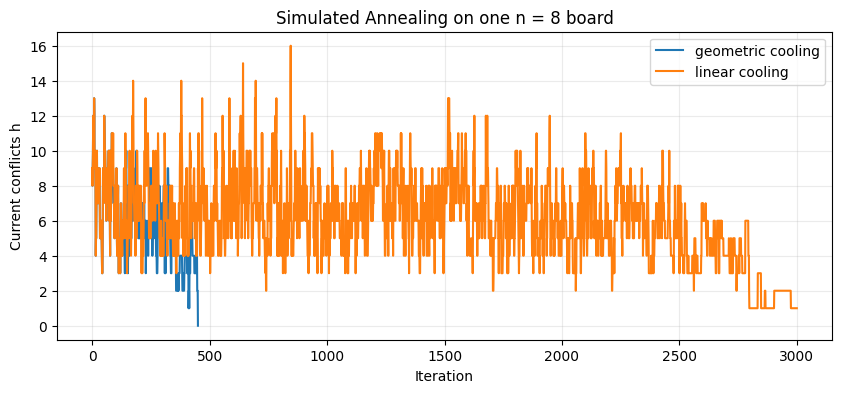

,Lich lam nguoi,h cuoi,So vong,Ti le chap nhan
0,geometric,0,450,0.529
1,linear,1,3000,0.526


In [23]:
import math

def simulated_annealing(board, T0=None, alpha=0.995, schedule="geometric", max_iter=None):
    """Solve n-Queens with SA and return the same result format as hill climbing."""
    board = np.array(board).copy()
    n = len(board)
    if T0 is None:
        T0 = max(1.0, float(n))
    if max_iter is None:
        max_iter = 375 * n
    if schedule not in {"geometric", "linear"}:
        raise ValueError("schedule must be 'geometric' or 'linear'")
    if T0 <= 0 or alpha <= 0 or alpha >= 1:
        raise ValueError("T0 must be positive and 0 < alpha < 1")

    e0 = EVALS
    cur = h(board)
    best_board, best_h = board.copy(), cur
    hist_h, hist_e, hist_T = [cur], [0], [T0]

    for i in range(max_iter):
        if cur == 0:
            break
        c, r = sample_neighbor(board)
        old = board[c]
        board[c] = r
        candidate_h = h(board)
        delta = candidate_h - cur
        temperature = T0 * (alpha ** i) if schedule == "geometric" else T0 * max(0.0, 1.0 - (i / max_iter))
        accept = delta <= 0 or (temperature > 1e-12 and np.random.random() < math.exp(-delta / temperature))
        if accept:
            cur = candidate_h
            if cur < best_h:
                best_h, best_board = cur, board.copy()
        else:
            board[c] = old
        hist_h.append(cur)
        hist_e.append(EVALS - e0)
        hist_T.append(temperature)

    # Returning the best state avoids losing a better solution found earlier.
    return make_result(best_board, best_h, len(hist_h) - 1, e0, hist_h, hist_e,
                       schedule=schedule, temperatures=hist_T,
                       stuck=None if best_h == 0 else "temperature/iteration limit")

# One reproducible visualization comparing the two cooling schedules.
np.random.seed(705)
sa_demo_board = random_board(8)
sa_demo = {}
for schedule in ("geometric", "linear"):
    np.random.seed(706)
    sa_demo[schedule] = simulated_annealing(sa_demo_board, schedule=schedule)

plt.figure(figsize=(10, 4))
for schedule, result in sa_demo.items():
    plt.plot(result["hist_h"], label=f"{schedule} cooling")
plt.xlabel("Iteration")
plt.ylabel("Current conflicts h")
plt.title("Simulated Annealing on one n = 8 board")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

pd.DataFrame([
    {"Lich lam nguoi": schedule, "h cuoi": result["h"], "So vong": result["iters"],
     "Ti le chap nhan": np.mean(np.diff(result["hist_h"]) != 0)}
    for schedule, result in sa_demo.items()
]).round(3)


## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [24]:
def run_many(alg, boards, seed, **kw):
    np.random.seed(seed)
    out = []
    for b in boards:
        t0 = time.perf_counter()
        result = alg(b, **kw)
        result["time"] = time.perf_counter() - t0
        out.append(result)
    return out

# Task 6: at least 100 different starting boards for each n and algorithm.
# The same boards are reused within an n so the comparison is paired and fair.
TASK6_RUNS = 200
TASK6_SCHEDULES = {"geometric": {"schedule": "geometric"}, "linear": {"schedule": "linear"}}

algorithms6 = {
    "Steepest asc. HC": (steepest_hc, {}),
    "Ineff. Stochastic HC": (inefficient_stochastic_hc, {}),
    "Efficient Stochastic HC": (stochastic_hc, {}),
    "Simulated Annealing (geometric)": (simulated_annealing, TASK6_SCHEDULES["geometric"]),
    "Simulated Annealing (linear)": (simulated_annealing, TASK6_SCHEDULES["linear"]),
}

boards_task6 = {}
for n_ in (4, 8):
    rng = np.random.RandomState(2026 + n_)
    boards_task6[n_] = [rng.randint(0, n_, size=n_) for _ in range(TASK6_RUNS)]

results_task6 = {}
for n_ in (4, 8):
    for name, (algorithm, kwargs) in algorithms6.items():
        results_task6[(name, n_)] = run_many(algorithm, boards_task6[n_], seed=9000 + n_, **kwargs)

rows_task6 = []
for (name, n_), results in results_task6.items():
    rows_task6.append({
        "Thuật toán": name,
        "n": n_,
        "Số lượt": len(results),
        "Thời gian TB (ms)": 1000 * np.mean([r["time"] for r in results]),
        "h cuối TB": np.mean([r["h"] for r in results]),
        "Thành công (%)": 100 * np.mean([r["h"] == 0 for r in results]),
        "Số đánh giá TB": np.mean([r["evals"] for r in results]),
    })

summary_task6 = pd.DataFrame(rows_task6).sort_values(["n", "Thuật toán"]).reset_index(drop=True)
summary_task6.round({"Thời gian TB (ms)": 3, "h cuối TB": 3, "Thành công (%)": 1, "Số đánh giá TB": 1})

,Thuật toán,n,Số lượt,Thời gian TB (ms),h cuối TB,Thành công (%),Số đánh giá TB
0,Efficient Stochastic HC,4,200,0.410,0.790,34.0,33.9
1,Ineff. Stochastic HC,4,200,0.220,0.795,37.0,30.4
2,Simulated Annealing (geometric),4,200,1.385,0.000,100.0,100.1
3,Simulated Annealing (linear),4,200,1.525,0.000,100.0,100.2
4,Steepest asc. HC,4,200,0.266,0.625,43.0,26.1
5,Efficient Stochastic HC,8,200,3.714,1.315,13.5,206.2
6,Ineff. Stochastic HC,8,200,3.781,1.315,15.0,326.4
7,Simulated Annealing (geometric),8,200,20.750,0.065,93.5,1156.2
8,Simulated Annealing (linear),8,200,60.500,0.640,36.0,2869.3
9,Steepest asc. HC,8,200,3.018,1.190,15.0,236.8


Bảng tổng hợp kết quả

In [26]:
N_RUNS = 200

def sa_budget(n):                       # ngân sách vòng lặp của SA theo kích thước bàn cờ
    return 375 * n

def make_algs(n):
    return {"Steepest asc. HC":        (steepest_hc, {}),
            "Ineff. Stochastic HC":    (inefficient_stochastic_hc, {}),
            "Efficient Stochastic HC": (stochastic_hc, {}),
            "Simulated Annealing (geometric)": (simulated_annealing, {"schedule": "geometric"})}

def run_many(alg, boards, seed, **kw):
    # Chạy alg trên từng bàn cờ trong boards; đo thời gian từng lượt.
    np.random.seed(seed)
    out = []
    for b in boards:
        t0 = time.perf_counter()
        r = alg(b, **kw)
        r['time'] = time.perf_counter() - t0
        out.append(r)
    return out

results6 = {}      # (tên thuật toán, n) -> list kết quả
boards6 = {}
for n_ in (4, 8):
    np.random.seed(500 + n_)
    boards6[n_] = [random_board(n_) for _ in range(N_RUNS)]
    for name, (alg, kw) in make_algs(n_).items():
        results6[(name, n_)] = run_many(alg, boards6[n_], seed=600 + n_, **kw)

rows = []
for (name, n_), rs in results6.items():
    rows.append(["n-Queens", f"n = {n_}", name, "Single run (200 lượt)", 100 * np.mean([r['h'] == 0 for r in rs]),
                 np.mean([r['h'] for r in rs]), 1000 * np.mean([r['time'] for r in rs]), np.mean([r['evals'] for r in rs])])
for _, r in rr_table.iterrows():
    rows.append(["n-Queens", f"n = {r['n']}", r["Thuật toán"] + " + Random Restart", "100 thử × ≤100 restart",
                 r["Thành công (/100)"], r["h cuối TB"], r["Thời gian TB (ms)"], r["Số lần đánh giá TB"]])
summary_nq = pd.DataFrame(rows, columns=["Bài toán", "Kích thước", "Thuật toán", "Số lượt / thiết lập", "Thành công (%)",
                                         "Xung đột cuối TB", "Thời gian TB (ms)", "Số lần đánh giá TB"])
summary_nq.sort_values(["Kích thước", "Số lượt / thiết lập"], ascending=[True, False], kind="stable").round(3).reset_index(drop=True)

,Bài toán,Kích thước,Thuật toán,Số lượt / thiết lập,Thành công (%),Xung đột cuối TB,Thời gian TB (ms),Số lần đánh giá TB
0,n-Queens,n = 4,Steepest asc. HC,Single run (200 lượt),46.0,0.635,0.216,26.920
1,n-Queens,n = 4,Ineff. Stochastic HC,Single run (200 lượt),27.5,0.880,1.703,32.440
2,n-Queens,n = 4,Efficient Stochastic HC,Single run (200 lượt),33.0,0.830,3.813,35.660
3,n-Queens,n = 4,Simulated Annealing (geometric),Single run (200 lượt),100.0,0.000,1.417,96.385
4,n-Queens,n = 4,Steepest HC + Random Restart,100 thử × ≤100 restart,100.0,0.000,0.542,60.210
5,n-Queens,n = 4,Ineff. Stochastic HC + Random Restart,100 thử × ≤100 restart,100.0,0.000,0.791,96.800
6,n-Queens,n = 4,Efficient Stochastic HC + Random Restart,100 thử × ≤100 restart,100.0,0.000,1.624,116.490
7,n-Queens,n = 8,Steepest asc. HC,Single run (200 lượt),16.5,1.230,2.517,232.000
8,n-Queens,n = 8,Ineff. Stochastic HC,Single run (200 lượt),14.5,1.295,3.183,324.960
9,n-Queens,n = 8,Efficient Stochastic HC,Single run (200 lượt),16.0,1.265,3.327,204.530


## Phan tich hoi tu va do phuc tap thuc nghiem

Phan nay ve do thi hoi tu h theo so vong lap cho mot luot chay dai dien tai n=8, dong thoi khao sat thoi gian chay theo n = {4, 8, 12, 16, 20} bang do thi log-log. Cac doan nam ngang tren do thi hoi tu bieu thi plateau. He so goc log-log la so mu thuc nghiem trong pham vi kich thuoc va cach cai dat dang khao sat.


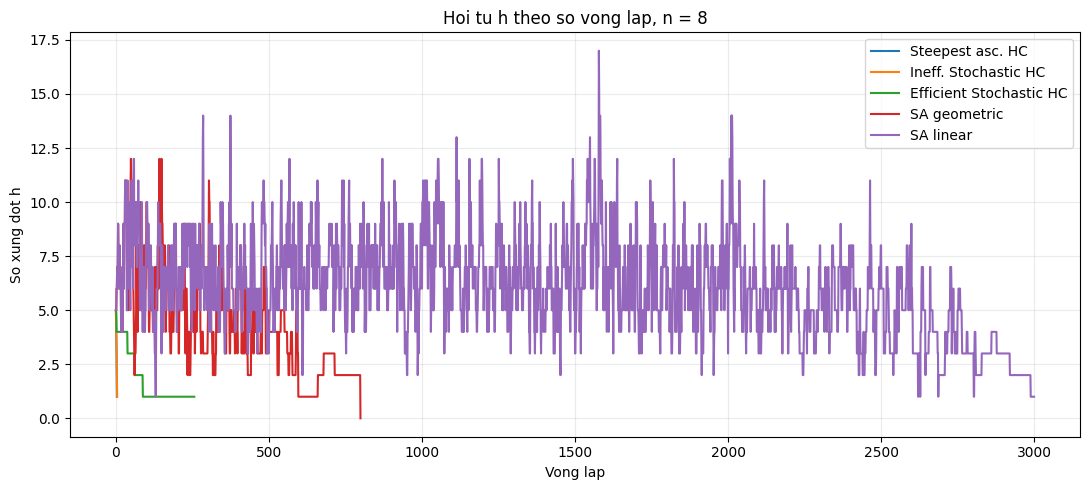

,Thuat toan,h dau,h cuoi,So vong,Vong cuoi co thay doi,So vong plateau
0,Steepest asc. HC,5,1,3,3,0
1,Ineff. Stochastic HC,5,1,4,4,0
2,Efficient Stochastic HC,5,1,256,88,252
3,SA geometric,5,0,799,799,530
4,SA linear,5,1,3000,2989,1419


In [ ]:
# Do thi hoi tu h theo so vong lap tai n = 8.
convergence_board = np.array([0, 5, 2, 7, 1, 3, 6, 4])
convergence_algs = {
    "Steepest asc. HC": (steepest_hc, {}),
    "Ineff. Stochastic HC": (inefficient_stochastic_hc, {}),
    "Efficient Stochastic HC": (stochastic_hc, {}),
    "SA geometric": (simulated_annealing, {"schedule": "geometric"}),
    "SA linear": (simulated_annealing, {"schedule": "linear"}),
}
convergence_results = {}
for name, (algorithm, kwargs) in convergence_algs.items():
    np.random.seed(8100)
    convergence_results[name] = algorithm(convergence_board, **kwargs)

plt.figure(figsize=(11, 5))
for name, result in convergence_results.items():
    plt.plot(result["hist_h"], label=name)
plt.xlabel("Vong lap")
plt.ylabel("So xung dot h")
plt.title("Hoi tu h theo so vong lap, n = 8")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

convergence_rows = []
for name, result in convergence_results.items():
    history = np.asarray(result["hist_h"])
    changes = np.flatnonzero(np.diff(history) != 0)
    convergence_rows.append({
        "Thuat toan": name, "h dau": int(history[0]), "h cuoi": int(result["h"]),
        "So vong": int(result["iters"]),
        "Vong cuoi co thay doi": int(changes[-1] + 1) if len(changes) else 0,
        "So vong plateau": int(len(history) - 1 - len(changes)),
    })
convergence_summary = pd.DataFrame(convergence_rows)
convergence_summary


### Do phuc tap thuc nghiem qua thoi gian chay

Do trung binh tren 3 ban co khoi tao cho moi n. Duong hoi quy tren he truc log-log giup uoc luong xu huong time ~ C*n^p; day la do phuc tap thuc nghiem, phu thuoc vao dieu kien dung, so lan danh gia ham muc tieu va cai dat.


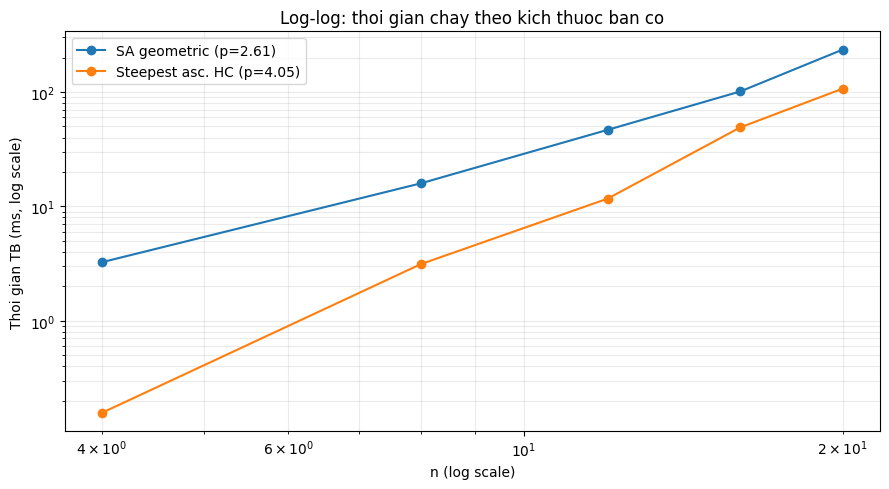

,Thuat toan,n,Thoi gian TB (ms),h cuoi TB
0,Steepest asc. HC,4,0.156100,0.666667
1,SA geometric,4,3.243567,0.000000
2,Steepest asc. HC,8,3.127333,1.000000
3,SA geometric,8,15.902533,0.000000
4,Steepest asc. HC,12,11.684600,1.333333
5,SA geometric,12,46.684700,0.000000
6,Steepest asc. HC,16,48.997333,1.333333
7,SA geometric,16,101.053300,0.000000
8,Steepest asc. HC,20,107.262467,2.333333
9,SA geometric,20,235.354433,0.333333


In [ ]:
SCALE_NS = [4, 8, 12, 16, 20]
SCALE_RUNS = 3
scaling_algs = {
    "Steepest asc. HC": (steepest_hc, {}),
    "SA geometric": (simulated_annealing, {"schedule": "geometric"}),
}
scaling_rows = []
for n_ in SCALE_NS:
    rng = np.random.RandomState(12000 + n_)
    boards = [rng.randint(0, n_, size=n_) for _ in range(SCALE_RUNS)]
    for name, (algorithm, kwargs) in scaling_algs.items():
        results = run_many(algorithm, boards, seed=13000 + n_, **kwargs)
        scaling_rows.append({"Thuat toan": name, "n": n_, "Thoi gian TB (ms)": 1000 * np.mean([r["time"] for r in results]), "h cuoi TB": np.mean([r["h"] for r in results])})
scaling_summary = pd.DataFrame(scaling_rows)

plt.figure(figsize=(9, 5))
scaling_exponents = {}
for name, group in scaling_summary.groupby("Thuat toan"):
    x = group["n"].to_numpy(float)
    y = group["Thoi gian TB (ms)"].to_numpy(float)
    slope, intercept = np.polyfit(np.log10(x), np.log10(y), 1)
    scaling_exponents[name] = slope
    plt.loglog(x, y, "o-", label=f"{name} (p={slope:.2f})")
plt.xlabel("n (log scale)")
plt.ylabel("Thoi gian TB (ms, log scale)")
plt.title("Log-log: thoi gian chay theo kich thuoc ban co")
plt.grid(which="both", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()
scaling_summary


## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?